# Confidence Intervals

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/confidence_intervals.md](../../notes/hypothesis_testing_and_confidence_intervals/confidence_intervals.md).

A confidence interval is built from a point estimate, a standard error, and a critical value. The confidence level is a statement about the *procedure*: over repeated samples, a 95% procedure captures the true parameter about 95% of the time. Here we build intervals from scratch and verify coverage by simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

## 1. A t-interval for a mean

Draw one sample of size 100 from $N(50, 5^2)$ and compute $\bar x \pm t^*_{n-1}\, s/\sqrt n$.

Sample mean = 50.405, 95% CI = (49.446, 51.365)


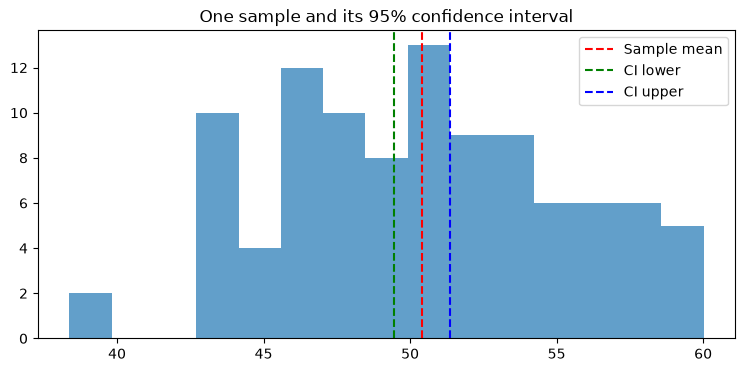

In [2]:
def mean_ci(data, confidence=0.95):
    n = len(data)
    mean = data.mean()
    se = data.std(ddof=1) / np.sqrt(n)
    t_crit = stats.t.ppf((1 + confidence) / 2, df=n - 1)
    return mean - t_crit * se, mean, mean + t_crit * se

true_mean, sd, n = 50, 5, 100
data = rng.normal(true_mean, sd, n)
lower, mean, upper = mean_ci(data)
print(f"Sample mean = {mean:.3f}, 95% CI = ({lower:.3f}, {upper:.3f})")

plt.figure(figsize=(9, 4))
plt.hist(data, bins=15, alpha=0.7)
plt.axvline(mean, color="red", linestyle="--", label="Sample mean")
plt.axvline(lower, color="green", linestyle="--", label="CI lower")
plt.axvline(upper, color="blue", linestyle="--", label="CI upper")
plt.title("One sample and its 95% confidence interval")
plt.legend()
plt.show()

Note that the interval is much narrower than the spread of the data: it describes the uncertainty about the *mean*, not where individual observations fall.

## 2. What "95%" means: coverage

We repeat the whole sampling-and-interval procedure 1,000 times and count how often the interval contains the true mean.

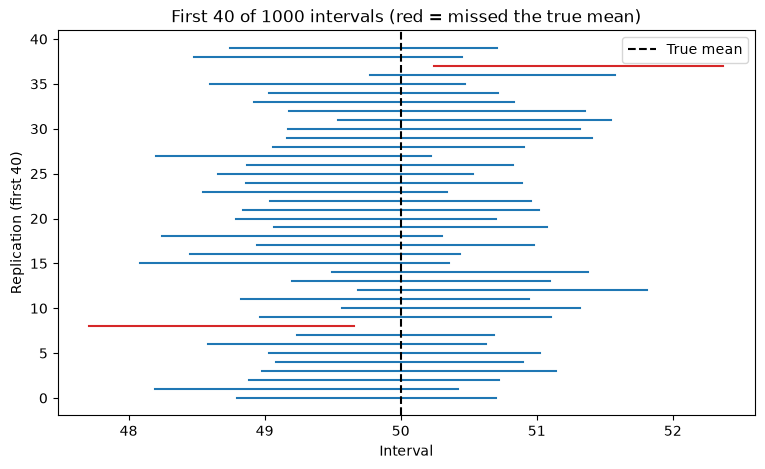

Empirical coverage: 0.941


In [3]:
reps = 1000
covered = 0
fig, ax = plt.subplots(figsize=(9, 5))
for i in range(reps):
    lo, m, hi = mean_ci(rng.normal(true_mean, sd, n))
    hit = lo <= true_mean <= hi
    covered += hit
    if i < 40:
        ax.plot([lo, hi], [i, i], color="tab:blue" if hit else "tab:red")
ax.axvline(true_mean, color="black", linestyle="--", label="True mean")
ax.set_xlabel("Interval")
ax.set_ylabel("Replication (first 40)")
ax.set_title("First 40 of 1000 intervals (red = missed the true mean)")
ax.legend()
plt.show()
print(f"Empirical coverage: {covered / reps:.3f}")

Coverage is close to 0.95. Any single interval either contains $\mu$ or it does not; the 95% describes the long-run hit rate.

## 3. Confidence level, sample size, and width

Width is $2\,t^*\,s/\sqrt n$. Raising the level widens the interval, and increasing $n$ narrows it like $1/\sqrt n$.

In [4]:
s = 5.0
print("Width by confidence level (n = 100):")
for level in (0.90, 0.95, 0.99):
    t_crit = stats.t.ppf((1 + level) / 2, 99)
    print(f"  {level:.0%}: {2 * t_crit * s / np.sqrt(100):.3f}")

print("Width by sample size (95%):")
for m in (25, 100, 400):
    t_crit = stats.t.ppf(0.975, m - 1)
    print(f"  n={m:4d}: {2 * t_crit * s / np.sqrt(m):.3f}")

Width by confidence level (n = 100):
  90%: 1.660
  95%: 1.984
  99%: 2.626
Width by sample size (95%):
  n=  25: 4.128
  n= 100: 1.984
  n= 400: 0.983


Quadrupling $n$ from 100 to 400 roughly halves the width, as the $1/\sqrt n$ rule predicts.

## 4. Interval for a proportion and a prediction interval

For a proportion, $\hat p \pm z^*\sqrt{\hat p(1-\hat p)/n}$. A prediction interval for one new observation adds the individual variability: $\bar x \pm t^* s\sqrt{1+1/n}$.

In [5]:
# Poll: 312 of 800 support a proposal
n_poll, successes = 800, 312
p_hat = successes / n_poll
se_p = np.sqrt(p_hat * (1 - p_hat) / n_poll)
z = stats.norm.ppf(0.975)
print(f"p_hat = {p_hat:.3f}, 95% CI = ({p_hat - z * se_p:.3f}, {p_hat + z * se_p:.3f})")

# Confidence versus prediction interval for the mean of a sample
sample = rng.normal(50, 10, 25)
xbar, s_ = sample.mean(), sample.std(ddof=1)
t_crit = stats.t.ppf(0.975, 24)
ci = (xbar - t_crit * s_ / 5, xbar + t_crit * s_ / 5)
pi = (xbar - t_crit * s_ * np.sqrt(1 + 1 / 25), xbar + t_crit * s_ * np.sqrt(1 + 1 / 25))
print(f"Mean CI:             ({ci[0]:.2f}, {ci[1]:.2f})")
print(f"Prediction interval: ({pi[0]:.2f}, {pi[1]:.2f})")

p_hat = 0.390, 95% CI = (0.356, 0.424)
Mean CI:             (44.77, 52.33)
Prediction interval: (29.28, 67.82)


## 5. Synthetic stock returns

To keep the notebook self-contained we simulate 252 daily returns (no market data is downloaded) and compute intervals for the mean daily return at three confidence levels. Daily returns are noisy relative to their mean, so with this seed all three intervals include zero even though the true mean is slightly positive.

90%: (-0.00192, 0.00198)
95%: (-0.00229, 0.00236)
99%: (-0.00303, 0.00310)


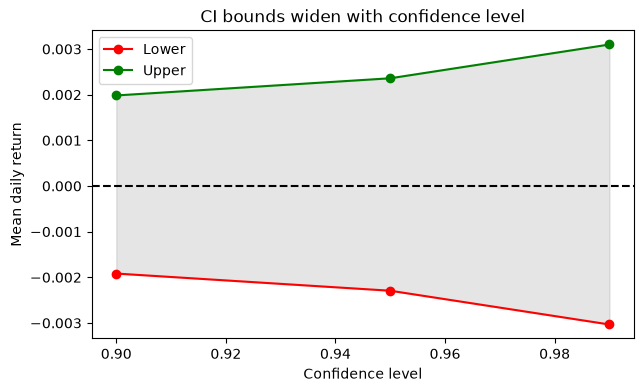

In [6]:
rng_s = np.random.default_rng(42)
returns = rng_s.normal(0.001, 0.02, 252)
levels = [0.90, 0.95, 0.99]
bounds = []
for level in levels:
    lo, m, hi = mean_ci(returns, level)
    bounds.append((lo, hi))
    print(f"{level:.0%}: ({lo:.5f}, {hi:.5f})")

plt.figure(figsize=(7, 4))
plt.plot(levels, [b[0] for b in bounds], "o-", color="red", label="Lower")
plt.plot(levels, [b[1] for b in bounds], "o-", color="green", label="Upper")
plt.fill_between(levels, [b[0] for b in bounds], [b[1] for b in bounds], color="gray", alpha=0.2)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Confidence level")
plt.ylabel("Mean daily return")
plt.title("CI bounds widen with confidence level")
plt.legend()
plt.show()